# 01 — CIFAR-100 Data Pipeline, Frozen ResNet-18 Embeddings & Imbalanced Splits

**Feature**: `F1` (`01-data-and-embeddings` | `EPIC-01`)  
**Architecture**: `AD-001` (Two-Tier Execution), `AD-004` (Scenario 1 & 2 Splits), `AD-008` (Thin Notebook Orchestration on Remote JupyterHub)

This notebook orchestrates the complete data foundation for **MCTS-HNM**:
1. Global deterministic seed initialization (`src.utils.seed.set_global_seed`).
2. Verification of the 20-superclass $\leftrightarrow$ 100-fine-class CIFAR-100 taxonomy (`src.data.cifar100_taxonomy`).
3. Download of CIFAR-100 and extraction/verification of frozen ResNet-18 `[N, 512]` feature embeddings across stratified `train` (`45,000`), `val` (`5,000`), and `test` (`10,000`) splits (`src.data.extract_embeddings`).
4. Construction and visual inspection of Scenario 1 (Imbalanced Binary One-vs-Rest across $\rho \in \{1:10, 1:50, 1:100\}$) and Scenario 2 (100-way Multi-class Curriculum) index pools (`src.data.splits`).

In [1]:
from pathlib import Path
import sys

# Ensure repository root is importable when running from notebooks/ on JupyterHub
REPO_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import torch

from src.utils.seed import set_global_seed
from src.utils.experiment_config import (
    ExecutionMode,
    ExperimentConfig,
    get_isolated_paths,
    print_execution_banner,
)
from src.data.cifar100_taxonomy import (
    CIFAR100_COARSE_CLASSES,
    CIFAR100_FINE_CLASSES,
    fine_to_coarse_tensor,
    get_cifar100_taxonomy,
)
from src.data.extract_embeddings import (
    extract_cifar100_embeddings,
    extract_or_generate_embeddings,
    load_embedding_cache,
)
from src.data.splits import (
    DEFAULT_SCENARIO1_TARGETS,
    IMBALANCE_RATIOS,
    build_scenario1_split,
    build_scenario2_split,
)

# Standardized execution mode: REAL by default for scientific runs; SMOKE for rapid validation
EXECUTION_MODE = ExecutionMode.REAL
config = ExperimentConfig(execution_mode=EXECUTION_MODE)
print_execution_banner(config, notebook_name="01_data_and_embeddings")
paths = get_isolated_paths(config)

SEED = set_global_seed(42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Repository root: {REPO_ROOT} | Seed: {SEED} | Device: {DEVICE}")


Repository root: /home/mlima/workspace/mcts-hnm | Seed: 42 | Device: cuda


## 1. Inspect CIFAR-100 Coarse-to-Fine Taxonomy (`20` Superclasses $\rightarrow$ `100` Fine Classes)

In [2]:
taxonomy = get_cifar100_taxonomy()
print(f"Fine classes: {len(taxonomy.fine_names)} | Coarse superclasses: {len(taxonomy.coarse_names)}")

for coarse_id in range(5):
    coarse_name = taxonomy.coarse_names[coarse_id]
    fine_names = [taxonomy.fine_names[fid] for fid in taxonomy.coarse_to_fine_ids[coarse_id]]
    print(f"  [{coarse_id:02d}] {coarse_name:<32s} -> {fine_names}")

Fine classes: 100 | Coarse superclasses: 20
  [00] aquatic_mammals                  -> ['beaver', 'dolphin', 'otter', 'seal', 'whale']
  [01] fish                             -> ['aquarium_fish', 'flatfish', 'ray', 'shark', 'trout']
  [02] flowers                          -> ['orchid', 'poppy', 'rose', 'sunflower', 'tulip']
  [03] food_containers                  -> ['bottle', 'bowl', 'can', 'cup', 'plate']
  [04] fruit_and_vegetables             -> ['apple', 'mushroom', 'orange', 'pear', 'sweet_pepper']


## 2. Extract or Reuse Cached Frozen ResNet-18 Embeddings (`[N, 512]`)

If `embeddings/cifar100_resnet18.pt` already exists on the JupyterHub volume (`overwrite=False`), `extract_cifar100_embeddings()` validates its shapes and integrity without repeating the CNN forward pass.

In [3]:
DATA_DIR = REPO_ROOT / "data"
CACHE_PATH = paths.embeddings_dir / "cifar100_resnet18.pt"

bundle = extract_or_generate_embeddings(
    config=config,
    data_dir=DATA_DIR,
    cache_path=CACHE_PATH,
    batch_size=256,
    val_fraction=0.1,
    seed=SEED,
    device=DEVICE,
    overwrite=False,
)

verified_bundle = load_embedding_cache(CACHE_PATH)
for split_name in ("train", "val", "test"):
    emb = verified_bundle[split_name]["embeddings"]
    fine = verified_bundle[split_name]["fine_labels"]
    coarse = fine_to_coarse_tensor(fine)
    print(f"{split_name.upper():<5s} | embeddings: {tuple(emb.shape)} ({emb.dtype}) | classes: {fine.unique().numel()} fine, {coarse.unique().numel()} coarse")


100%|██████████| 169M/169M [07:41<00:00, 366kB/s] 


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /home/mlima/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 90.5MB/s]


TRAIN | embeddings: (45000, 512) (torch.float32) | classes: 100 fine, 20 coarse
VAL   | embeddings: (5000, 512) (torch.float32) | classes: 100 fine, 20 coarse
TEST  | embeddings: (10000, 512) (torch.float32) | classes: 100 fine, 20 coarse


## 3. Scenario 1 (One-vs-Rest Imbalanced Binary) & Scenario 2 (100-Way Multi-Class) Splits

In [4]:
train_fine_labels = verified_bundle["train"]["fine_labels"]
scenario2 = build_scenario2_split(train_fine_labels)
print(f"Scenario 2 active pool: {scenario2.active_indices.size} samples across {len(scenario2.class_to_indices)} fine classes.")

summary_rows = []
for target_name in DEFAULT_SCENARIO1_TARGETS:
    for ratio_label, pos_frac in IMBALANCE_RATIOS.items():
        s1 = build_scenario1_split(
            fine_labels=train_fine_labels,
            target_class=target_name,
            pos_fraction=pos_frac,
            seed=SEED,
        )
        summary_rows.append((target_name, ratio_label, s1.positive_indices.size, s1.negative_indices.size))

for target_name, ratio_label, n_pos, n_neg in summary_rows[:6]:
    print(f"Target: {target_name:<14s} | Ratio {ratio_label:<5s} | Positives: {n_pos:<4d} | Negatives (99 classes): {n_neg}")

Scenario 2 active pool: 45000 samples across 100 fine classes.
Target: beaver         | Ratio 1:10  | Positives: 45   | Negatives (99 classes): 44550
Target: beaver         | Ratio 1:50  | Positives: 9    | Negatives (99 classes): 44550
Target: beaver         | Ratio 1:100 | Positives: 4    | Negatives (99 classes): 44550
Target: oak_tree       | Ratio 1:10  | Positives: 45   | Negatives (99 classes): 44550
Target: oak_tree       | Ratio 1:50  | Positives: 9    | Negatives (99 classes): 44550
Target: oak_tree       | Ratio 1:100 | Positives: 4    | Negatives (99 classes): 44550


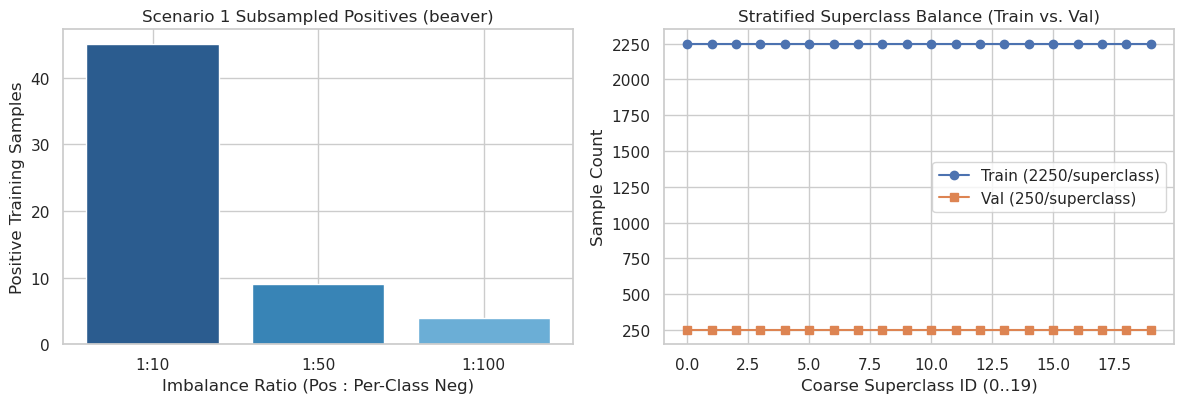

In [5]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

# Left: Scenario 1 positive count per imbalance ratio
ratios = list(IMBALANCE_RATIOS.keys())
pos_counts = [
    build_scenario1_split(train_fine_labels, DEFAULT_SCENARIO1_TARGETS[0], IMBALANCE_RATIOS[r], seed=SEED).positive_indices.size
    for r in ratios
]
axes[0].bar(ratios, pos_counts, color=["#2b5c8f", "#3884b6", "#6baed6"])
axes[0].set_title(f"Scenario 1 Subsampled Positives ({DEFAULT_SCENARIO1_TARGETS[0]})")
axes[0].set_xlabel("Imbalance Ratio (Pos : Per-Class Neg)")
axes[0].set_ylabel("Positive Training Samples")

# Right: Stratified train vs val samples per superclass
train_coarse = verified_bundle["train"]["coarse_labels"].numpy()
val_coarse = verified_bundle["val"]["coarse_labels"].numpy()
axes[1].plot(np.bincount(train_coarse, minlength=20), label="Train (2250/superclass)", marker="o")
axes[1].plot(np.bincount(val_coarse, minlength=20), label="Val (250/superclass)", marker="s")
axes[1].set_title("Stratified Superclass Balance (Train vs. Val)")
axes[1].set_xlabel("Coarse Superclass ID (0..19)")
axes[1].set_ylabel("Sample Count")
axes[1].legend()

plt.tight_layout()
plt.show()